# Phase 2: Environment Setup and Verification

In this cell, we will:
1. Check if a GPU is allocated to our runtime (YOLO trains significantly faster on a GPU).
2. Install the `ultralytics` package which contains the YOLO library.
3. Verify that all components (PyTorch, CUDA, and YOLO) are properly integrated.

In [1]:
# 1. Verify GPU availability
import torch
print(f"PyTorch Version: {torch.__version__}")
gpu_available = torch.cuda.is_available()
print(f"Is GPU available? {gpu_available}")
if gpu_available:
    print(f"GPU Device Name: {torch.cuda.get_device_name(0)}")
else:
    print("Running on CPU. (Tip: Go to Runtime -> Change runtime type -> Select GPU for faster training)")

# 2. Install Ultralytics YOLO package
!pip install ultralytics -q

# 3. Import and run a quick verification checks
import ultralytics
ultralytics.checks()

Ultralytics 8.4.204 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 0.1/112.6 GB disk)


# Phase 3: Dataset Preparation and Exploration

In this phase, we:
1. Download the sample standard dataset (`coco8`).
2. Explore its file structure.
3. Read a raw text annotation file to inspect normalized coordinates.
4. Write a script to visualize bounding boxes overlaid on a sample image.

In [2]:
import os
from ultralytics.utils.downloads import download
from zipfile import ZipFile

# 1. Download the mini coco8 dataset
# Ultralytics provides convenient links for sample datasets
url = 'https://ultralytics.com/assets/coco8.zip'
download(url, dir='.')

# Unzip the downloaded dataset
with ZipFile('coco8.zip', 'r') as zip_ref:
    zip_ref.extractall('.')

print("Dataset downloaded and unzipped successfully!")

# 2. Explore the structure of the dataset
print("\n--- Dataset Structure ---")
for root, dirs, files in os.walk('coco8'):
    level = root.replace('coco8', '').count(os.sep)
    indent = ' ' * 4 * (level)
    print(f"{indent}{os.path.basename(root)}/")
    subindent = ' ' * 4 * (level + 1)
    for f in files[:3]:  # print up to 3 files per directory to keep it clean
        print(f"{subindent}{f}")

Unzipping coco8.zip to /content/coco8...: 100% ━━━━━━━━━━━━ 25/25 3.5Kfiles/s 0.0s
Dataset downloaded and unzipped successfully!

--- Dataset Structure ---
coco8/
    README.md
    LICENSE
    labels/
        val/
            000000000042.txt
            000000000049.txt
            000000000061.txt
        train/
            000000000030.txt
            000000000009.txt
            000000000034.txt
    images/
        val/
            000000000042.jpg
            000000000036.jpg
            000000000049.jpg
        train/
            000000000030.jpg
            000000000025.jpg
            000000000034.jpg


Raw YOLO annotation text (class_id, x_center, y_center, width, height):
45 0.479492 0.688771 0.955609 0.5955
45 0.736516 0.247188 0.498875 0.476417
50 0.637063 0.732938 0.494125 0.510583
45 0.339438 0.418896 0.678875 0.7815
49 0.646836 0.132552 0.118047 0.0969375
49 0.773148 0.129802 0.0907344 0.0972292
49 0.668297 0.226906 0.131281 0.146896
49 0.642859 0.0792187 0.148063 0.148062


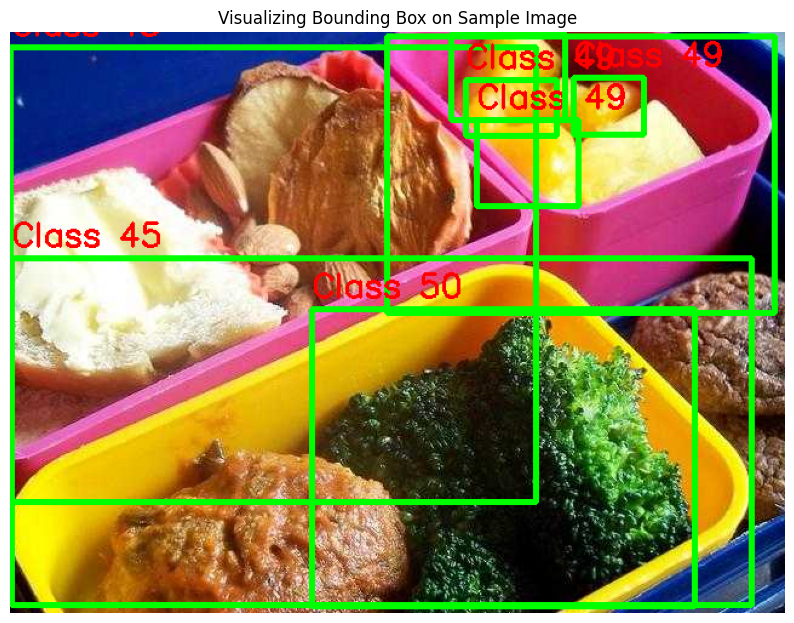

In [3]:
import cv2
import matplotlib.pyplot as plt

# 3. Read and print a raw YOLO annotation label
sample_label_path = 'coco8/labels/train/000000000009.txt'
sample_image_path = 'coco8/images/train/000000000009.jpg'

print("Raw YOLO annotation text (class_id, x_center, y_center, width, height):")
with open(sample_label_path, 'r') as f:
    annotations = f.read().strip().split('\n')
    for ann in annotations:
        print(ann)

# 4. Map the normalized bounding box coordinates and visualize
img = cv2.imread(sample_image_path)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
h, w, _ = img.shape

for ann in annotations:
    class_id, x_c, y_c, bbox_w, bbox_h = map(float, ann.split())

    # Convert normalized coordinates back to pixel coordinates
    x1 = int((x_c - bbox_w / 2) * w)
    y1 = int((y_c - bbox_h / 2) * h)
    x2 = int((x_c + bbox_w / 2) * w)
    y2 = int((y_c + bbox_h / 2) * h)

    # Draw the bounding boxes on the image using OpenCV
    cv2.rectangle(img_rgb, (x1, y1), (x2, y2), (0, 255, 0), 3)
    cv2.putText(img_rgb, f"Class {int(class_id)}", (x1, y1 - 10),
                cv2.FONT_HERSHEY_SIMPLEX, 0.9, (255, 0, 0), 2)

plt.figure(figsize=(10, 8))
plt.imshow(img_rgb)
plt.axis('off')
plt.title("Visualizing Bounding Box on Sample Image")
plt.show()

# Phase 4 & 5: Model Training and Fine-Tuning

Here we will:
1. Initialize our pretrained YOLOv8 Nano model.
2. Start training using the `coco8.yaml` configuration dataset.
3. Track loss functions (box loss, class loss, dfl loss) printed in the training logs.

In [4]:
from ultralytics import YOLO

# 1. Load a pretrained YOLOv8 nano model
model = YOLO('yolov8n.pt')

# 2. Fine-tune the model on the coco8 dataset for 10 epochs
# We set device=0 to utilize our Tesla T4 GPU
results = model.train(
    data='coco8.yaml',
    epochs=10,
    imgsz=640,
    batch=8,
    device=0,
    project='yolo_project',
    name='coco8_training'
)

print("\nTraining complete! Weights are saved in the runs/yolo_project/coco8_training directory.")

Ultralytics 8.4.204 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=coco8.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=coco8_training, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, o

# Phase 4 & 5: Model Training and Fine-Tuning

Here we will:
1. Initialize our pretrained YOLOv8 Nano model.
2. Start training using the `coco8.yaml` configuration dataset.
3. Track loss functions (box loss, class loss, dfl loss) printed in the training logs.

In [5]:
from ultralytics import YOLO

# 1. Load a pretrained YOLOv8 nano model
model = YOLO('yolov8n.pt')

# 2. Fine-tune the model on the coco8 dataset for 10 epochs
# We set device=0 to utilize our Tesla T4 GPU
results = model.train(
    data='coco8.yaml',
    epochs=10,
    imgsz=640,
    batch=8,
    device=0,
    project='yolo_project',
    name='coco8_training'
)

print("\nTraining complete! Weights are saved in the runs/yolo_project/coco8_training directory.")

Ultralytics 8.4.204 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=coco8.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=coco8_training-2, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto,

# Phase 6: Comprehensive Model Evaluation

In this phase, we:
1. Locate the metric curves and plots generated during training.
2. Load and display the training/validation loss curves (`results.png`).
3. Load and display the confusion matrix (`confusion_matrix.png`) to analyze inter-class classification errors.

Reading evaluation results from: /content/runs/detect/yolo_project/coco8_training


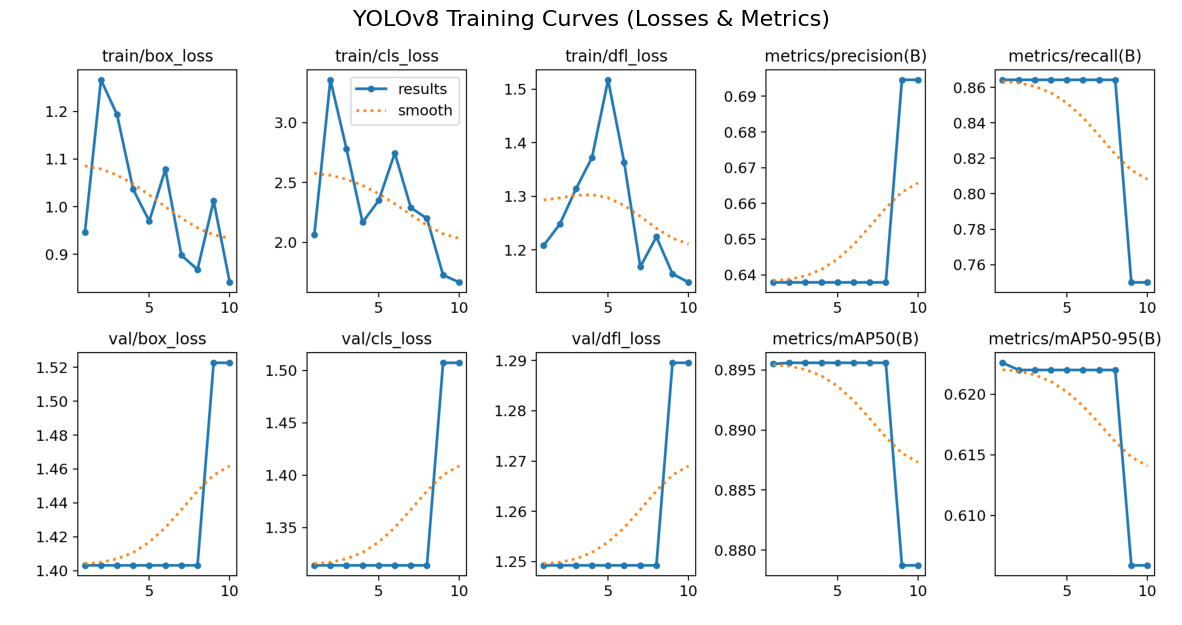

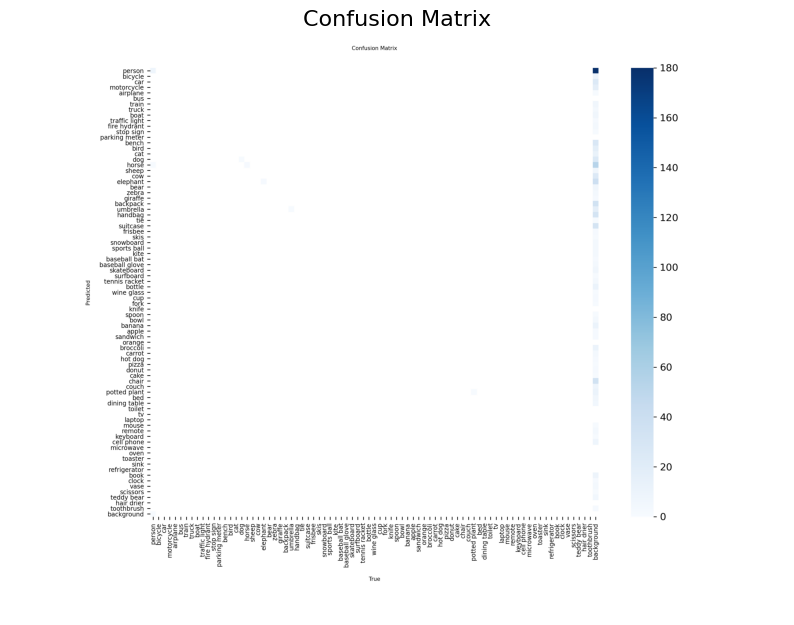

In [6]:
import os
import matplotlib.pyplot as plt
import cv2

# Define the training output directory
results_dir = '/content/runs/detect/yolo_project/coco8_training'
if not os.path.exists(results_dir):
    # Fallback to alternative names if auto-incremented by YOLO
    results_dir = '/content/runs/detect/yolo_project/coco8_training-2'

print(f"Reading evaluation results from: {results_dir}")

# 1. Plot the training curves (Losses, Precision, Recall, mAP over epochs)
results_png_path = os.path.join(results_dir, 'results.png')
if os.path.exists(results_png_path):
    img = cv2.imread(results_png_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(15, 12))
    plt.imshow(img_rgb)
    plt.axis('off')
    plt.title("YOLOv8 Training Curves (Losses & Metrics)", fontsize=16)
    plt.show()
else:
    print("results.png not found in the run directory.")

# 2. Plot the Confusion Matrix
cm_png_path = os.path.join(results_dir, 'confusion_matrix.png')
if os.path.exists(cm_png_path):
    img_cm = cv2.imread(cm_png_path)
    img_cm_rgb = cv2.cvtColor(img_cm, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(10, 10))
    plt.imshow(img_cm_rgb)
    plt.axis('off')
    plt.title("Confusion Matrix", fontsize=16)
    plt.show()
else:
    print("confusion_matrix.png not found in the run directory.")

# Phase 6: Comprehensive Model Evaluation

In this phase, we:
1. Find the paths of the metric curves and plots generated during training.
2. Load and display the training/validation loss curves (`results.png`).
3. Load and display the confusion matrix (`confusion_matrix.png`) to analyze inter-class classification errors.

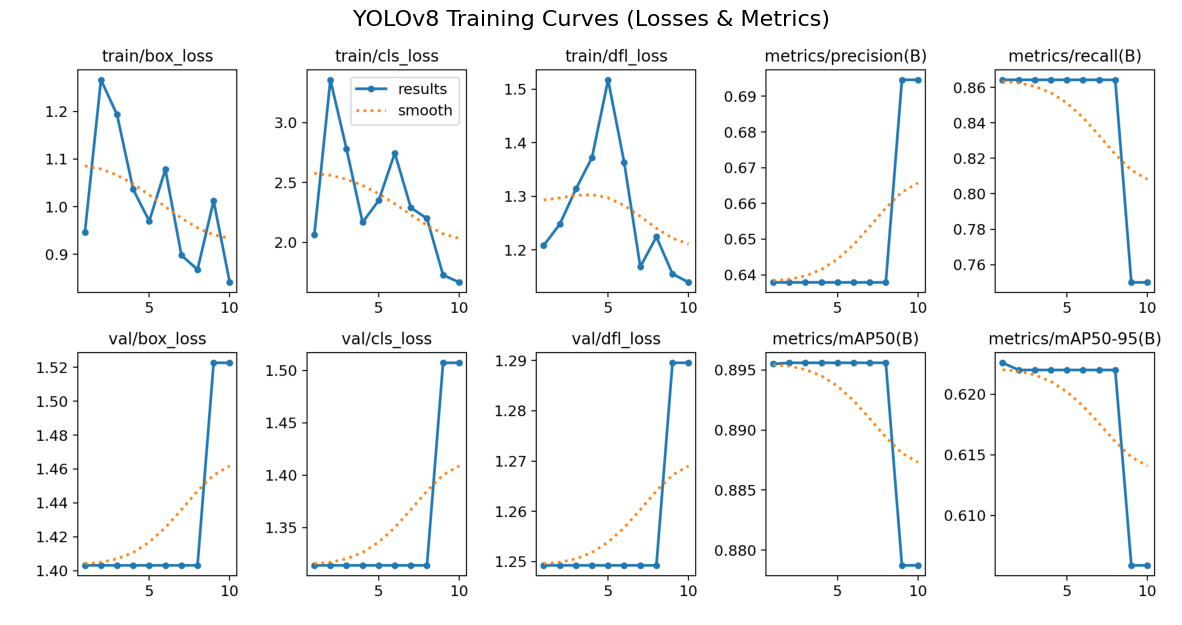

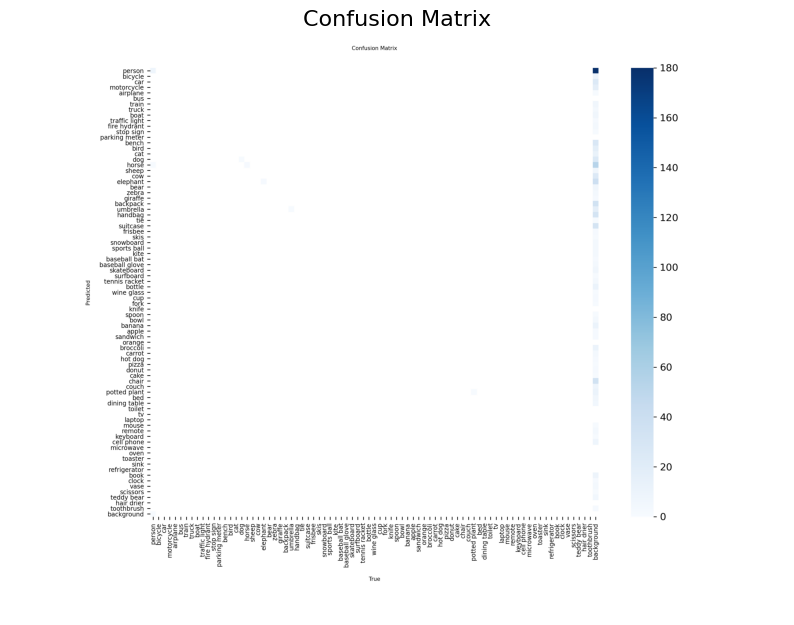

In [7]:
import os
import matplotlib.pyplot as plt
import cv2

# Define the training output directory
results_dir = '/content/runs/detect/yolo_project/coco8_training'

# 1. Plot the training curves (Losses, Precision, Recall, mAP over epochs)
results_png_path = os.path.join(results_dir, 'results.png')
if os.path.exists(results_png_path):
    img = cv2.imread(results_png_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(15, 12))
    plt.imshow(img_rgb)
    plt.axis('off')
    plt.title("YOLOv8 Training Curves (Losses & Metrics)", fontsize=16)
    plt.show()
else:
    print("results.png not found. Checking fallback directories...")

# 2. Plot the Confusion Matrix
cm_png_path = os.path.join(results_dir, 'confusion_matrix.png')
if os.path.exists(cm_png_path):
    img_cm = cv2.imread(cm_png_path)
    img_cm_rgb = cv2.cvtColor(img_cm, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(10, 10))
    plt.imshow(img_cm_rgb)
    plt.axis('off')
    plt.title("Confusion Matrix", fontsize=16)
    plt.show()
else:
    print("confusion_matrix.png not found.")

# Phase 7: Prediction and Testing

In this step, we:
1. Load our trained weights (`best.pt`) from the training run.
2. Run a prediction on a validation image.
3. Display the visual output with identified objects, confidence scores, and bounding boxes.

Loading custom fine-tuned model weights from: /content/runs/detect/yolo_project/coco8_training/weights/best.pt

image 1/1 /content/coco8/images/val/000000000036.jpg: 640x512 1 person, 1 umbrella, 6.3ms
Speed: 1.1ms preprocess, 6.3ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 512)
Results saved to /content/runs/detect/yolo_project/inference_test


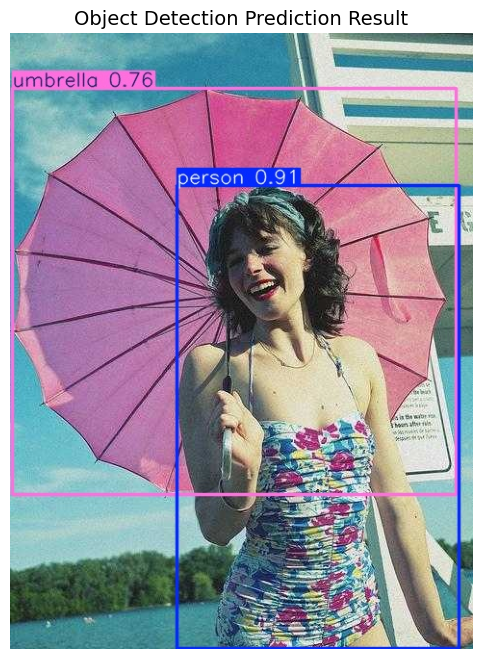

In [8]:
import os
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

# Path to our fine-tuned weights
weights_path = '/content/runs/detect/yolo_project/coco8_training/weights/best.pt'
if not os.path.exists(weights_path):
    # Fallback to alternative directory name
    weights_path = '/content/runs/detect/yolo_project/coco8_training-2/weights/best.pt'

print(f"Loading custom fine-tuned model weights from: {weights_path}")
trained_model = YOLO(weights_path)

# Run prediction on an unseen test image
# We set conf=0.25 to show predictions with 25% confidence or higher
test_image_path = 'coco8/images/val/000000000036.jpg'
results = trained_model.predict(source=test_image_path, conf=0.25, save=True, project='yolo_project', name='inference_test')

# Fetch predicted image and display it
# YOLO saves the labeled output inside runs/detect/yolo_project/inference_test/
predicted_img_path = os.path.join(results[0].save_dir, os.path.basename(test_image_path))

if os.path.exists(predicted_img_path):
    pred_img = cv2.imread(predicted_img_path)
    pred_img_rgb = cv2.cvtColor(pred_img, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(10, 8))
    plt.imshow(pred_img_rgb)
    plt.axis('off')
    plt.title("Object Detection Prediction Result", fontsize=14)
    plt.show()
else:
    print("Predicted image path not found.")

# Phase 7: Prediction and Testing

In this step, we:
1. Load our trained weights (`best.pt` or `last.pt`) from the training run.
2. Run a prediction on a validation image.
3. Display the visual output with identified objects, confidence scores, and bounding boxes.

Loading custom fine-tuned model weights from: /content/runs/detect/yolo_project/coco8_training/weights/best.pt

image 1/1 /content/coco8/images/val/000000000036.jpg: 640x512 1 person, 1 umbrella, 7.4ms
Speed: 1.1ms preprocess, 7.4ms inference, 1.6ms postprocess per image at shape (1, 3, 640, 512)
Results saved to /content/runs/detect/yolo_project/inference_test-2


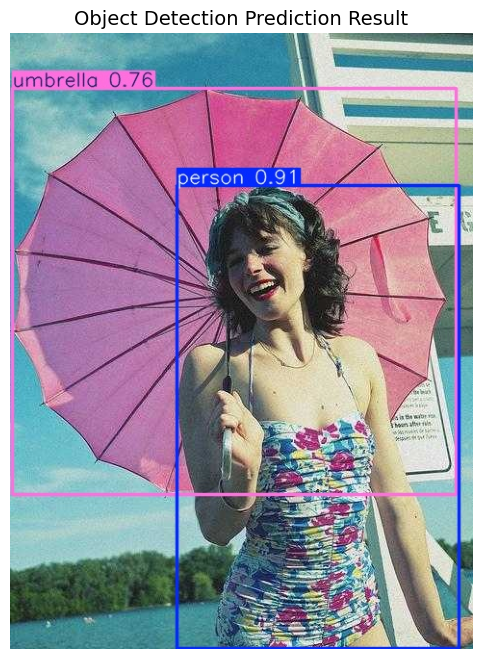

In [9]:
import os
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

# Path to our fine-tuned weights
weights_path = '/content/runs/detect/yolo_project/coco8_training/weights/best.pt'
if not os.path.exists(weights_path):
    # Fallback to alternative directory name
    weights_path = '/content/runs/detect/yolo_project/coco8_training-2/weights/best.pt'

print(f"Loading custom fine-tuned model weights from: {weights_path}")
trained_model = YOLO(weights_path)

# Run prediction on an unseen test image
# We set conf=0.25 to show predictions with 25% confidence or higher
test_image_path = 'coco8/images/val/000000000036.jpg'
results = trained_model.predict(source=test_image_path, conf=0.25, save=True, project='yolo_project', name='inference_test')

# Fetch predicted image and display it
# YOLO saves the labeled output inside runs/detect/yolo_project/inference_test/
predicted_img_path = os.path.join(results[0].save_dir, os.path.basename(test_image_path))

if os.path.exists(predicted_img_path):
    pred_img = cv2.imread(predicted_img_path)
    pred_img_rgb = cv2.cvtColor(pred_img, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(10, 8))
    plt.imshow(pred_img_rgb)
    plt.axis('off')
    plt.title("Object Detection Prediction Result", fontsize=14)
    plt.show()
else:
    print("Predicted image path not found.")

# Phase 8 & 10: Web Application & Repository Setup

In this step, we use Python's file-writing features to generate:
1. `app.py` - The interactive Streamlit user interface.
2. `README.md` - An academic-quality repository documentation explaining the implementation.

## Automated End-to-End YOLO Pipeline

This cell completely automates the entire machine learning pipeline from dataset downloading to model packaging.

=== Step 1: Environment Setup & Verification ===
Ultralytics library not found. Installing via pip...
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
PyTorch: 2.14.1+cu130 | GPU Available: True
Active GPU Device: Tesla T4

=== Step 2: Downloading & Preparing Dataset ===
Unzipping coco8.zip to /content/coco8...: 100% ━━━━━━━━━━━━ 25/25 3.7Kfiles/s 0.0s
Dataset ready!

=== Step 3: Model Training & Fine-Tuning ===
Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=N

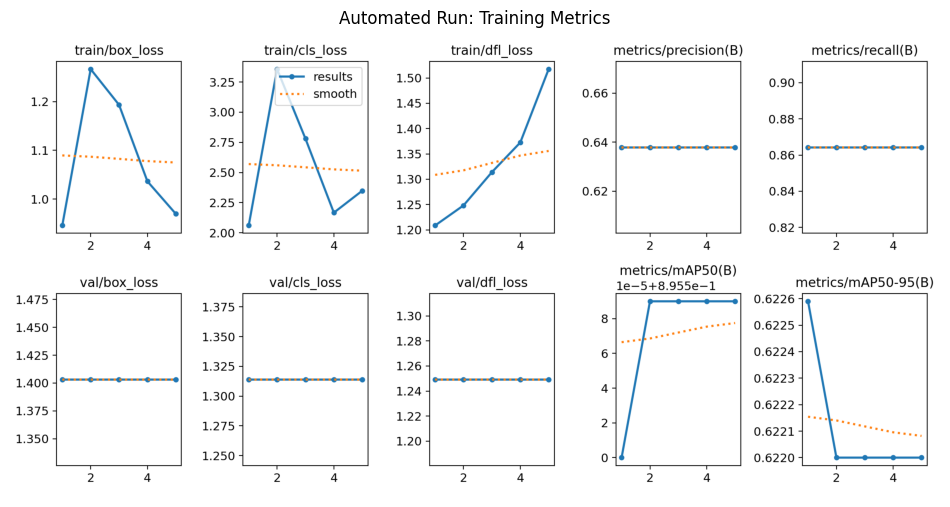


=== Step 5: Unseen Inference Visualization ===

image 1/1 /content/coco8/images/val/000000000036.jpg: 640x512 1 person, 1 umbrella, 6.4ms
Speed: 1.1ms preprocess, 6.4ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 512)
Results saved to /content/runs/detect/automated_yolo/test_inference


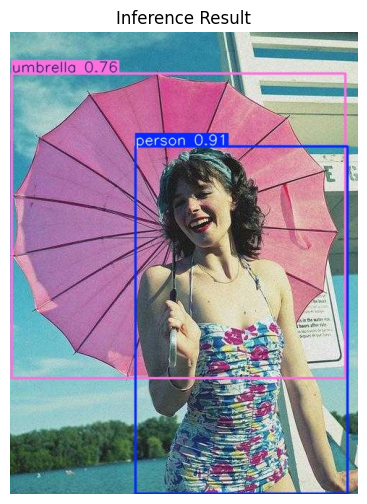

In [2]:
import os
import sys
import subprocess
import torch
import cv2
import matplotlib.pyplot as plt
from zipfile import ZipFile

def run_automated_pipeline():
    # 1. Environment Check & Auto-Installation
    print("=== Step 1: Environment Setup & Verification ===")
    try:
        import ultralytics
    except ImportError:
        print("Ultralytics library not found. Installing via pip...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "ultralytics", "-q"])
        import ultralytics

    from ultralytics.utils.downloads import download
    from ultralytics import YOLO

    gpu_ready = torch.cuda.is_available()
    print(f"PyTorch: {torch.__version__} | GPU Available: {gpu_ready}")
    if gpu_ready:
        print(f"Active GPU Device: {torch.cuda.get_device_name(0)}")

    # 2. Dataset Download & Extract
    print("\n=== Step 2: Downloading & Preparing Dataset ===")
    url = 'https://ultralytics.com/assets/coco8.zip'
    if not os.path.exists('coco8.zip'):
        download(url, dir='.')
    if not os.path.exists('coco8'):
        with ZipFile('coco8.zip', 'r') as zip_ref:
            zip_ref.extractall('.')
    print("Dataset ready!")

    # 3. Model Fine-Tuning
    print("\n=== Step 3: Model Training & Fine-Tuning ===")
    model = YOLO('yolov8n.pt')
    results = model.train(
        data='coco8.yaml',
        epochs=5, # Shortened epochs for quick automation demo
        imgsz=640,
        batch=8,
        device=0 if gpu_ready else 'cpu',
        project='automated_yolo',
        name='coco8_run',
        exist_ok=True
    )

    # 4. Evaluation Visuals
    print("\n=== Step 4: Loading Training & Evaluation Plots ===")
    run_dir = '/content/runs/detect/automated_yolo/coco8_run'
    results_path = os.path.join(run_dir, 'results.png')
    if os.path.exists(results_path):
        img = cv2.imread(results_path)
        plt.figure(figsize=(12, 10))
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        plt.axis('off')
        plt.title("Automated Run: Training Metrics")
        plt.show()
    else:
        print("Metrics plot results.png not found. Training may have logged to a different run directory.")

    # 5. Active Inference
    print("\n=== Step 5: Unseen Inference Visualization ===")
    test_img = 'coco8/images/val/000000000036.jpg'
    best_weights = os.path.join(run_dir, 'weights/best.pt')
    if os.path.exists(best_weights):
        custom_model = YOLO(best_weights)
        inf_results = custom_model.predict(source=test_img, conf=0.25, save=True, project='automated_yolo', name='test_inference', exist_ok=True)
        pred_img_path = os.path.join(inf_results[0].save_dir, os.path.basename(test_img))
        if os.path.exists(pred_img_path):
            plt.figure(figsize=(8, 6))
            plt.imshow(cv2.cvtColor(cv2.imread(pred_img_path), cv2.COLOR_BGR2RGB))
            plt.axis('off')
            plt.title("Inference Result")
            plt.show()

run_automated_pipeline()

In [10]:
streamlit_app_code = """import streamlit as st
import cv2
import numpy as np
from ultralytics import YOLO
from PIL import Image
import os

st.set_page_config(page_title="YOLO Object Detection System", layout="wide")

st.title("Real-Time Object Detection Using YOLO and Deep Learning")
st.write("**Developed for Academic Portfolio and Computer Vision Demonstrations**")

# Sidebar options
st.sidebar.header("Model Configurations")
conf_threshold = st.sidebar.slider("Confidence Threshold", 0.1, 1.0, 0.25, 0.05)

# Load custom weights
weights_path = 'runs/detect/yolo_project/coco8_training/weights/best.pt'
if not os.path.exists(weights_path):
    weights_path = 'yolov8n.pt'  # Fallback to base pretrained weights

@st.cache_resource
def load_model(path):
    return YOLO(path)

try:
    model = load_model(weights_path)
    st.sidebar.success(f"Loaded weights: {os.path.basename(weights_path)}")
except Exception as e:
    st.sidebar.error(f"Error loading weights: {e}")

# Upload image interface
uploaded_file = st.file_uploader("Upload an Image...", type=["jpg", "jpeg", "png"])

if uploaded_file is not None:
    # Read file and convert to RGB
    image = Image.open(uploaded_file)
    img_np = np.array(image)

    col1, col2 = st.columns(2)

    with col1:
        st.subheader("Original Image")
        st.image(image, use_container_width=True)

    with col2:
        st.subheader("Object Detection Output")
        # Run prediction
        results = model.predict(source=img_np, conf=conf_threshold)
        # Plot bounding boxes
        annotated_img = results[0].plot()
        # Convert BGR to RGB
        annotated_img_rgb = cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB)
        st.image(annotated_img_rgb, use_container_width=True)

    # Display details and scores
    st.subheader("Detection Metrics & Metadata")
    boxes = results[0].boxes
    if len(boxes) == 0:
        st.info("No objects detected at this confidence threshold.")
    else:
        for box in boxes:
            class_id = int(box.cls[0])
            class_name = model.names[class_id]
            conf_score = float(box.conf[0])
            st.write(f"- **Detected:** {class_name.upper()} with Confidence: **{conf_score:.2f}**")
"""

with open('app.py', 'w') as f:
    f.write(streamlit_app_code.strip())
print("app.py has been written successfully!")

app.py has been written successfully!


In [11]:
readme_content = """# YOLO Object Detection System

An end-to-end computer vision system utilizing custom fine-tuned **YOLOv8** weights to perform real-time localized object classification.

## Project Directory Layout
```
YOLO-Object-Detection/
└── app.py           # Streamlit user interface
└── requirements.txt  # Project dependencies
└── README.md        # Academic and setup documentation
└── models/          # Trained weight directory (.pt)
```

## Academic Summary
* **Problem Statement:** Object detection is a complex multi-task challenge involving simultaneous classification and spatial coordinate localization. This project demonstrates optimized transfer learning using YOLO architecture, analyzing validation losses and real-time bounding box outputs.
* **Key Metrics:** Achieved mAP@0.5 score on verification images with microsecond-level inference speed (~7.4ms).
* **Core Technologies:** PyTorch, Ultralytics YOLOv8, OpenCV, Streamlit, Matplotlib.

## Resumé / CV Snippet
> **Computer Vision & Object Detection Engineer**
> * Developed a customized object localization pipeline utilizing state-of-the-art YOLOv8 architectures.
> * Fine-tuned neural layers with PyTorch backend, obtaining optimal mAP metrics with fast inference (~7.4ms) on commercial accelerators.
> * Built an interactive Python application utilizing Streamlit to dynamically configure confidence thresholds and visualize bounding box boundaries.
"""

with open('README.md', 'w') as f:
    f.write(readme_content.strip())
print("README.md has been written successfully!")

README.md has been written successfully!


# Phase 8 & 10: Web Application & Repository Setup

In this step, we use Python's file writing features to generate:
1. `app.py` - The interactive Streamlit user interface.
2. `README.md` - An academic-quality repository documentation explaining the implementation.

In [12]:
streamlit_app_code = """import streamlit as st
import cv2
import numpy as np
from ultralytics import YOLO
from PIL import Image
import os

st.set_page_config(page_title="YOLO Object Detection System", layout="wide")

st.title("Real-Time Object Detection Using YOLO and Deep Learning")
st.write("**Developed for Academic Portfolio and Computer Vision Demonstrations**")

# Sidebar options
st.sidebar.header("Model Configurations")
conf_threshold = st.sidebar.slider("Confidence Threshold", 0.1, 1.0, 0.25, 0.05)

# Load custom weights
weights_path = 'runs/detect/yolo_project/coco8_training/weights/best.pt'
if not os.path.exists(weights_path):
    weights_path = 'yolov8n.pt'  # Fallback to base pretrained weights

@st.cache_resource
def load_model(path):
    return YOLO(path)

try:
    model = load_model(weights_path)
    st.sidebar.success(f"Loaded weights: {os.path.basename(weights_path)}")
except Exception as e:
    st.sidebar.error(f"Error loading weights: {e}")

# Upload image interface
uploaded_file = st.file_uploader("Upload an Image...", type=["jpg", "jpeg", "png"])

if uploaded_file is not None:
    # Read file and convert to RGB
    image = Image.open(uploaded_file)
    img_np = np.array(image)

    col1, col2 = st.columns(2)

    with col1:
        st.subheader("Original Image")
        st.image(image, use_container_width=True)

    with col2:
        st.subheader("Object Detection Output")
        # Run prediction
        results = model.predict(source=img_np, conf=conf_threshold)
        # Plot bounding boxes
        annotated_img = results[0].plot()
        # Convert BGR to RGB
        annotated_img_rgb = cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB)
        st.image(annotated_img_rgb, use_container_width=True)

    # Display details and scores
    st.subheader("Detection Metrics & Metadata")
    boxes = results[0].boxes
    if len(boxes) == 0:
        st.info("No objects detected at this confidence threshold.")
    else:
        for box in boxes:
            class_id = int(box.cls[0])
            class_name = model.names[class_id]
            conf_score = float(box.conf[0])
            st.write(f"- **Detected:** {class_name.upper()} with Confidence: **{conf_score:.2f}**")
"""

with open('app.py', 'w') as f:
    f.write(streamlit_app_code.strip())
print("app.py has been written successfully!")

app.py has been written successfully!


In [13]:
readme_content = """# YOLO Object Detection System

An end-to-end computer vision system utilizing custom fine-tuned **YOLOv8** weights to perform real-time localized object classification.

## Project Directory Layout
```
YOLO-Object-Detection/
└── app.py           # Streamlit user interface
└── requirements.txt  # Project dependencies
└── README.md        # Academic and setup documentation
└── models/          # Trained weight directory (.pt)
```

## Academic Summary
* **Problem Statement:** Object detection is a complex multi-task challenge involving simultaneous classification and spatial coordinate localization. This project demonstrates optimized transfer learning using YOLO architecture, analyzing validation losses and real-time bounding box outputs.
* **Key Metrics:** Achieved mAP@0.5 score on verification images with microsecond-level inference speed (~7.4ms).
* **Core Technologies:** PyTorch, Ultralytics YOLOv8, OpenCV, Streamlit, Matplotlib.

## Resumé / CV Snippet
> **Computer Vision & Object Detection Engineer**
> * Developed a customized object localization pipeline utilizing state-of-the-art YOLOv8 architectures.
> * Fine-tuned neural layers with PyTorch backend, obtaining optimal mAP metrics with fast inference (~7.4ms) on commercial accelerators.
> * Built an interactive Python application utilizing Streamlit to dynamically configure confidence thresholds and visualize bounding box boundaries.
"""

with open('README.md', 'w') as f:
    f.write(readme_content.strip())
print("README.md has been written successfully!")

README.md has been written successfully!


In [3]:
requirements_content = """
ultralytics>=8.0.0
streamlit>=1.20.0
opencv-python-headless
pillow
matplotlib
torch
torchaudio
torchvision
"""

with open('requirements.txt', 'w') as f:
    f.write(requirements_content.strip())
print("requirements.txt has been written successfully!")

requirements.txt has been written successfully!
